<a href="https://colab.research.google.com/github/muhammad-usman-tech/data-analysis-tasks/blob/main/claud_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

total duplicates : 0
--- Data Coverage Grid (Number of orders per month) ---
month_id  1   2    3   4    5   6   7    8   9    10   11   12
year_id                                                       
2003      39  41   50  58   58  46  50   58  76  158  296   70
2004      91  86   56  64   74  85  91  133  95  159  301  110
2005      99  97  106  56  120   0   0    0   0    0    0    0


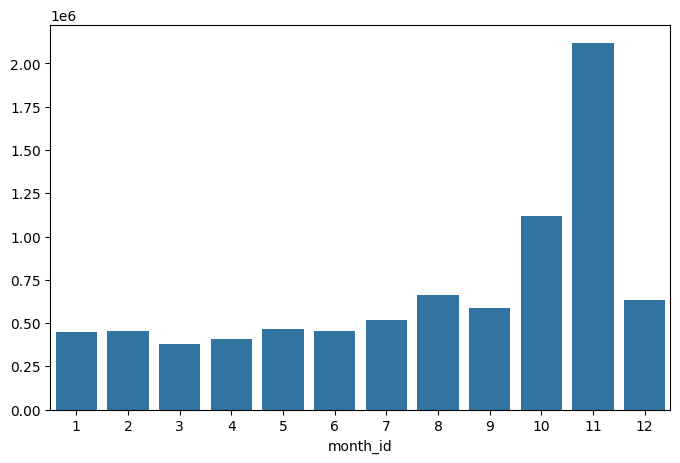

Top 10 Customers Revenue Breakdown:


,sales
customername,
Euro Shopping Channel,912294.11
Mini Gifts Distributors Ltd.,654858.06
"Australian Collectors, Co.",200995.41
Muscle Machine Inc,197736.94
La Rochelle Gifts,180124.90
"Dragon Souveniers, Ltd.",172989.68
Land of Toys Inc.,164069.44
The Sharp Gifts Warehouse,160010.27
"AV Stores, Co.",157807.81


Total Revenue: $10,032,628.85
Revenue from Top 10: $2,954,882.75 (29.45% of total)
Revenue from Top 3: $1,768,147.58 (17.62% of total)


,count
country,
USA,696
Spain,227
France,224
Australia,125
UK,90
Italy,73
Singapore,68
Norway,60
Finland,59


In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

# importing the data
df=pd.read_csv('/content/sales_data_sample.csv',encoding='latin1')

# inspecting the data
df.shape
# got 2823 rows and 25 columns
# df.info()
df.head()
df.tail()
# order number is unique it sholuld be taken as it is

df['ORDERNUMBER'].nunique()
# this we got 307 unique order numbers means this data is single order transaction data as we can also see the order line number

# and yes all the data types are perfect except of one order date

# ===============================================================ETL=====
obj_columns=df.select_dtypes(include='object').columns
for col in obj_columns:
  df[col]=df[col].str.strip()
df=df.replace(['ERROR','','UNKNOWN'],np.nan)
# here collecting more nan for counting all the nan later

df.columns=(df.columns.str.lower()
.str.replace(r'[^a-z0-9]+','_',regex=True)
.str.strip('_'))

# now changing the order date data type
df['orderdate']=pd.to_datetime(df['orderdate'],format='mixed')


# now working with the duplicates

print('total duplicates :',df.duplicated().sum())
# no duplicates found but we will not check the duplicates in the order number column because its a single order transaction data so this column can contains the duplicates
# yes we can drop order id rows if they dont have any order id because transaction with out order id is not valid or we can tag it as without order id
# but our order id data is all fill


# now working with the null's
nulls=df.isnull().sum()
percent_nulls=(nulls/len(df))*100
percent_nulls
nulls_containing=percent_nulls[percent_nulls>0]
# len(nulls_containing)

# 4 columns have null values and as your ETL instruction we will check ane by one and see if we have need to drop it or fill it with the clear reasons
percent_nulls
# 1st one is state with 52 percent and state is not much more important column because some countries does not follow it we can both or fill the data in it
# the best is to drop but as we have 48 percent of the data and some countries follo the state and difficult to locate so we can just fill it with 'unknown' or 'notmentioned'

df['state']=df['state'].fillna('unknown')
percent_nulls
# now again address line code is 89 percent missed and mostly people's address hav fit in the address line 1 so can leave it as it is because droping can drop the other 11 address line 2 data that can be usefull for locating some one's address
# leave it as it is or can just fill for clarification
df['addressline2']=df['addressline2'].fillna('notmentioned')
# next is territory which is again not important to drop because it is macro region and some countries can be easily searched on its basis and just filling it for the clarification
df['territory']=df['territory'].fillna('notmentioned')

# and the last is postal code and its 2 percent missing and according to me some times it is important to locate some one on the basis of the postal code so a it is also the obj so jus replace it with the not given
df['postalcode']=df['productcode'].fillna('not_given')

nulls=df.isnull().sum()
percent_nulls=(nulls/len(df))*100
percent_nulls
nulls_containing=percent_nulls[percent_nulls>0]
# len(nulls_containing)
# got 0

# checking or having a look from my side
df['orderdate'].max()
# Timestamp('2005-05-31 )
df['orderdate'].min()
# Timestamp('2003-01-06 00:00:00')
df['year_id'].value_counts()
# ok
# validation and ETL IS DONE
df.to_csv('cleaned_data.csv',index=False)


# ok continuing from here
# Q1:Which product lines make us the most money? Is that the same list as the ones customers order the most units of?
#  Where should next quarter’s marketing budget go?
# code:
df.groupby('productline')['sales'].sum().sort_values(ascending=False)
# Classic Cars	3919615.66

df['productline'].value_counts().sort_values(ascending=False)
# Classic Cars	967

# Yes Classic Cars is the product line that gave us the most money and its the most selling product line
# and the list of most profitable product vs most selling is almost same just from top to classis to vintage to further but the truck are more selling but givving us less revenue as compare to planes
# and yes last thing we have to spend the next month quarter budget to train (a product line) which has the lowest profit and the sales of just 77


# Q2:
coverage_check = pd.crosstab(df['year_id'], df['month_id'])
print("--- Data Coverage Grid (Number of orders per month) ---")
print(coverage_check)


df['YEAR_MONTH'] = df['orderdate'].dt.to_period('M')

# 2. Sum the SALES revenue for each unique month
monthly_revenue = df.groupby('YEAR_MONTH')['sales'].sum().reset_index()
monthly_revenue['YEAR_MONTH']=monthly_revenue['YEAR_MONTH'].dt.to_timestamp()


# ok so now go for the yearly trend
df_trend=df[df['year_id'].isin([2003,2004])]
data=df_trend.groupby('month_id')['sales'].sum()
plt.figure(figsize=(8,5))
sns.barplot(x=data.index,y=data.values)
plt.show()
# month 11 and 10 and 12 shows the highest sales month as they are the holidays and month 3 has the lowest sales


# Q3:Who are our top 10 customers, and what share of total revenue do they bring in? How bad would it be if we lost the top 3?
# ok so we can here groupby by the different things but we are gonna use the customernamebecause its the single transaction data

total_revenue = df['sales'].sum()
cus_data = df.groupby('customername')['sales'].sum().sort_values(ascending=False)
top_10_customers = cus_data.head(10)
top_10_revenue = top_10_customers.sum()
top_10_share = (top_10_revenue / total_revenue) * 100

top_3_revenue = top_10_customers.head(3).sum()
top_3_share = (top_3_revenue / total_revenue) * 100

print("Top 10 Customers Revenue Breakdown:")
display(top_10_customers)
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Revenue from Top 10: ${top_10_revenue:,.2f} ({top_10_share:.2f}% of total)")
print(f"Revenue from Top 3: ${top_3_revenue:,.2f} ({top_3_share:.2f}% of total)")

# additional calculation
top_5=top_10_customers.head(5).sum()
top_5_share=(top_5/total_revenue)*100
top_5_share
top_5

# Total Revenue: $10,032,628.85
# Revenue from Top 10: $2,954,882.75 (29.45% of total)
# Revenue from Top 3: $1,768,147.58 (17.62% of total)
# np.float64(2146009.42 top 5 has 21 percent of the data


# Q4:
countries_data=df.groupby('country')['sales'].sum().sort_values(ascending=False)
terri_data=df.groupby('territory')['sales'].sum().sort_values(ascending=False)
terri_data

# territory	 top 2 out of 4
# EMEA	4979272.41
# notmentioned	3852061.39
countries_data
# top 4
# USA	3627982.83
# Spain	1215686.92
# France	1110916.52
# Australia	630623.10
# by country we got usa but by territory we got EMEA at the top

data_4=df.groupby('country').agg(

                                Total_revenue=('sales','sum'),
                                total_orders=("ordernumber",'nunique'),
                                total_items=('quantityordered','sum')
).reset_index()

data_4['revenue_per_order']=data_4['Total_revenue']/data_4['total_orders']

data_4=data_4.sort_values(by='Total_revenue',ascending=False)


data_4
# it is clearly observed that the usa and the Spain are at the top 2 in revenue generation

# 18	USA	3627982.83	112	35659	32392.703839
# 14	Spain	1215686.92	36	12429	33769.081111

# now we have to check which country are according to many oreder or max revenue per order
data_4.sort_values(by='total_orders',ascending=False)
# we got USA then france then spain
# by total orders
data_4.sort_values(by='revenue_per_order',ascending=False)
# found an pattern according to the order per revenue the europian countries
# 16	Switzerland	117713.56	2	1078	58856.780000
# 9	Italy	374674.31	8	3773	46834.288750
# 17	UK	478880.46	13	5013	36836.958462
# ok so the usa and france and the spain are top in the total revenue as they are top 3 in the total_revenue and the most orders but on the other hand
# the countries have mas revenue per order like swizerland italy and UK they have are less in orders and also in total revenue but they are good and top in the orderper revenue

# the mian thing to undestand is after even getting the max order per revenue they are very less in the total _ revenue because of their less number of orders like 2 or 3(but remember there are mush more countries below this like IRELAND)

# so by just increasing the sales here can increase the revenue here
# Basically, I am watching almost things are little in a pattern, in a cool pattern. Like which countries have you can say total revenue they definitely have most orders per country, like USA, France, and Spain. We have got them like a little difference, but they are top three. That's good. But if we will talk about the order per revenue, definitely in Spain or like Ireland or maybe sorry Finland, Switzerland, Italy, and UK. I think these are the countries that are on the top. On the other hand, these are in the like total order or total revenue. They are not in the bottom. Ireland, like these country, and Singapore are on the bottom. These are like almost on the middle or like near to the bottom. So it does not show a very clear like which countries have total revenue they also have a very much total orders, and they also have maximum total order per maximum revenue per order, like things are little different. It totally depend upon the definitely price of the product, like in the USA people are purchasing cheap products, but much in numbers, so that's why that's increasing the total revenue.

# Q5:
df['status'].value_counts()
# Cancelled, Disputed or On Hold
data_5=df[df['status'].isin(['Cancelled', 'Disputed', 'On Hold'])]
data_5['sales'].sum()
# 445679 this amount is affecting

data_5.groupby('status')['productline'].value_counts().sort_values(ascending=False)
# Cancelled	Ships	18
# Classic Cars	16
# Vintage Cars	13
# Planes	12
# On Hold	Classic Cars	12
# Planes	9
# Vintage Cars	9
# Ships	8
# Disputed	Motorcycles	6
# On Hold	Trucks and Buses	4
# Disputed	Classic Cars	3
# Planes	2
# Vintage Cars	2
# Cancelled	Trains	1
# Disputed	Ships	1
# On Hold	Motorcycles	1
# Trains	1

data_5.groupby('productline')['status'].value_counts().sort_values(ascending=False)
# total Ships	Cancelled	are 18 and Classic Cars	Cancelled	16
# and on hold these Classic Cars	On Hold	12 # Vintage Cars	On Hold	9
# and disputed Motorcycles	Disputed	6 and  Classic Cars	Disputed	3
# Answer Classic Cars are almost the most in the Canceled and the disputed and also on the hold
data_5.groupby('productline')['ordernumber'].nunique().sort_values(ascending=False)
# Final answer: Classic Cars	7
# Vintage Cars	7
# Ships	5 these 3 are the most top of cancelled and the disputed and the on hold
# so the cars customers and the ships customer are most effected we should identify whats the issue with the classis cars specialy
df.groupby('productline')['sales'].sum().sort_values(ascending=False)
# and here i would like to ad an info that these cars are even on the top of generating sales
# Classic Cars	3919615.66
# Vintage Cars	1903150.84
# if we wil clear these hold and cancelled or disputed these product line is going to be super(also they are expensive)
df.groupby('productline')['ordernumber'].nunique().sort_values(ascending=False)
# one more info
# Classic Cars	199
# Vintage Cars	175 are the most sellng products

expensive_products = df.groupby('productline').agg(
    Avg_Sticker_Price=('msrp', 'mean'),
    Max_Sticker_Price=('msrp', 'max'),
    Avg_Actual_Price=('priceeach', 'mean'),
    Max_Actual_Price=('priceeach', 'max')
).reset_index()
expensive_products

# ok so the max price of each product line is max 100 but at the top is classic cars

# i know i did some extra searching in the Q5

# Q6:
low_data=df[df['priceeach']<df['msrp']]
low_data.shape
# here i got 1953, 26 which means we are salling the less then msrp and i can make us in the loss
low_data['productline'].value_counts()
# Classic Cars	801
# Vintage Cars	378
# Trucks and Buses	233
# Motorcycles	220
# Planes	172
# Ships	118
# Trains	31
low_data['ordernumber'].nunique()
# there are 295 unique orders
low_data['quantityordered'].sum() #69067
# answer : yes we are selling products below the msrp(in all the product lines) and the number one is  # Classic Cars	801
# and some countries are just giving this discount not all
low_data['country'].value_counts()
# USA	696
# Spain	227
# France	224
# Australia	125
# UK	90
# Italy	73
# Singapore	68
# Norway	60
# and it is happening most in the usa
# Okay, so as we are watching, uh, the last thing from the question 6 is does discounting go with the bigger deals? Yes, as we watched the classical cards are the most selling product code. And you can say these are the most revenue generating products. These are the most cancelled products, definitely these, because these are most in demand. And definitely if we are watching price below the MSRP, these are in that data. Some people like most in the USA are selling it like below the MSRP, that shouldn't that is not the good thing. Like it should be equal or something greater than the MSRP discount should be given with the bigger deals. But not below the MSRP, I guess.


# Part-7:



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ordernumber       2823 non-null   int64         
 1   quantityordered   2823 non-null   int64         
 2   priceeach         2823 non-null   float64       
 3   orderlinenumber   2823 non-null   int64         
 4   sales             2823 non-null   float64       
 5   orderdate         2823 non-null   datetime64[ns]
 6   status            2823 non-null   object        
 7   qtr_id            2823 non-null   int64         
 8   month_id          2823 non-null   int64         
 9   year_id           2823 non-null   int64         
 10  productline       2823 non-null   object        
 11  msrp              2823 non-null   int64         
 12  productcode       2823 non-null   object        
 13  customername      2823 non-null   object        
 14  phone             2823 n